# Resultados del candidato final: Conv + BiLSTM conjunta vs BiRNN

Compara los dos modelos entrenados con `candidato_final.ipynb`: **10 épocas**, `class_weight_power = 0.25`
y weight decay 0.1 en la BiRNN de puntuación, con todos los datos (61.912 instancias de train).

Cada modelo se entrenó en su propia corrida del pipeline:

- `models/2026-11-18__01-46-37/`: `bidirectional_rnn` (una red por problema).
- `models/2026-11-18__02-41-48/`: `joint_conv_bilstm` (una sola red para las 3 tareas).

El notebook las junta en `models/2026-11-18__candidato_final/metrics.json` y guarda cada gráfico en PNG y PDF en
`models/2026-11-18__candidato_final/poster/`.

**Se compara sobre control**: test ya se usó para elegir la época de cada red, así que su F1 es optimista.

In [1]:
import os
from pathlib import Path

# El notebook corre desde notebooks/experiments/: subimos hasta la raíz del repo para importar src
while not Path("pyproject.toml").exists():
    os.chdir("..")

import json

import matplotlib.pyplot as plt
from IPython.display import display

from notebooks.experiments import candidato_final_plots as C
from src.poster import plots as P

%matplotlib inline

/home/sebastian/personal/uba/Aprendizaje-Automatico-UBA/tp/TP2-Aprendizaje-Automatico-UBA/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Configuración

In [2]:
RUNS = [Path("models/2026-11-18__01-46-37"), Path("models/2026-11-18__02-41-48")]
# Corridas previas contra las que se compara: la de todo el dataset con 5 épocas y la local de 15 épocas
PREVIOUS = [Path("models/2026-11-16__21-24-10"), Path("models/2026-11-16__13-37-08")]
SPLIT = "control"  # "control" (recomendado) o "test"

RUN_DIR = Path("models/2026-11-18__candidato_final")
OUT_DIR = RUN_DIR / "poster"


def show_and_save(fig, name: str, caption: bool = True) -> None:
    """Muestra el gráfico y lo guarda en OUT_DIR como PNG y PDF"""
    if caption:
        P.add_caption(fig, CAPTION)
    P.save_figure(fig, OUT_DIR, name)
    display(fig)
    plt.close(fig)

In [3]:
report = C.merge_runs(RUNS)
RUN_DIR.mkdir(parents=True, exist_ok=True)
(RUN_DIR / "metrics.json").write_text(json.dumps(report, ensure_ascii=False, indent=1), encoding="utf-8")

config = report["config"]
print("Corridas:", config["merged_from"])
print("Épocas:", config["n_epochs"], "· class_weight_power:", config["class_weight_power"],
      "· weight decay BiRNN:", config["bidirectional_rnn_weight_decay"])
CAPTION = P.data_caption(report)
print(CAPTION)
print()
for split in ("control", "test"):
    print(f"F1 macro en {split}")
    print(P.f1_table(report, split))
    print()

Corridas: ['2026-11-18__01-46-37', '2026-11-18__02-41-48']
Épocas: 10 · class_weight_power: 0.25 · weight decay BiRNN: {'CapitalizationProblem': 0.0, 'PunctuationProblem': 0.1}
Datos: train 61.912 instancias (2.011.914 palabras), test 15.477, control 19.347 por problema · ventanas de 5–60 palabras · redes: 10 épocas

F1 macro en control
modelo                            Capitalización  Puntuación inicial    Puntuación final  promedio
Conv + BiLSTM conjunta                     0.758               0.844               0.701     0.767
BiRNN                                      0.698               0.814               0.633     0.715

F1 macro en test
modelo                            Capitalización  Puntuación inicial    Puntuación final  promedio
Conv + BiLSTM conjunta                     0.744               0.851               0.703     0.766
BiRNN                                      0.675               0.823               0.635     0.711



## 1. ¿Mejoró respecto de las corridas anteriores?

F1 macro de cada tarea contra el mejor resultado previo del mismo modelo (para cada problema, la corrida previa
con mejor promedio).

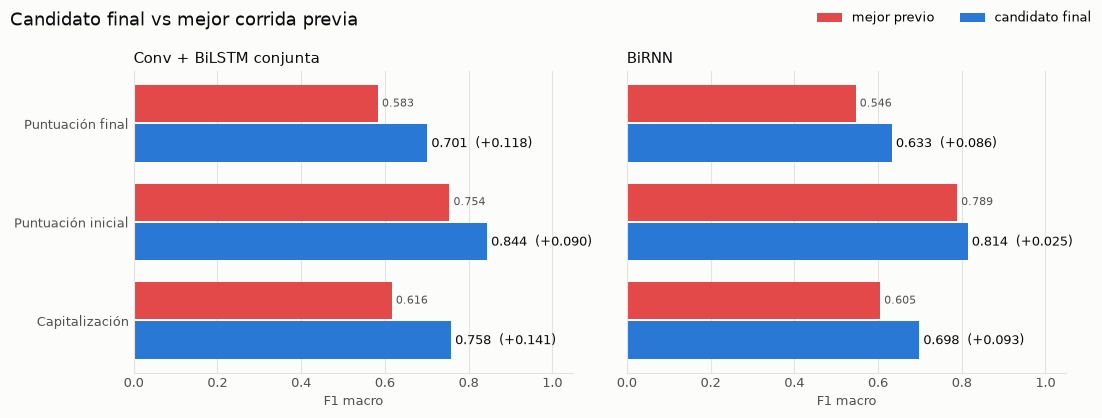

In [4]:
before = C.best_previous(PREVIOUS, SPLIT)
after = C.control_scores(report, SPLIT)
show_and_save(C.plot_before_after(before, after), "1_antes_vs_despues", caption=False)

## 2. F1 macro por tarea

Es la métrica del enunciado. Los modelos van del mejor (arriba) al peor según el promedio de las 3 tareas.

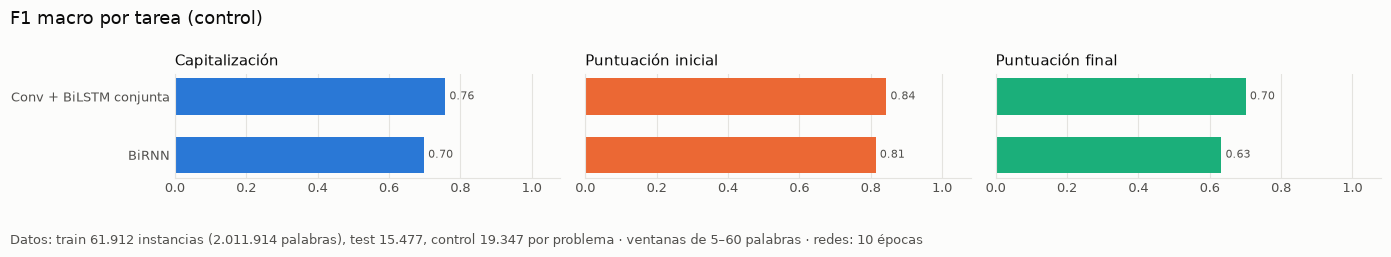

In [5]:
show_and_save(P.plot_f1_by_task(report, SPLIT), "2_f1_por_tarea")

## 3. Curvas de aprendizaje: ¿subajusta o sobreajusta?

F1 macro de cada tarea por época, en train (punteado) y test (lleno). Si las dos curvas suben juntas, el modelo
todavía puede aprender más; si train sigue subiendo y test se estanca o baja, empieza a sobreajustar. El punto
grande es la época con la que se quedó cada red (en la conjunta, elegida con el promedio de las 3 tareas).

**Ojo al comparar train con test**: el F1 de train se calcula durante el entrenamiento, con dropout activo, y el de
test sin dropout. Por eso en la conjunta (dropout 0.3) test puede quedar por encima de train, como en puntuación. La
BiRNN no tiene dropout, así que en ella la brecha sí mide sobreajuste.

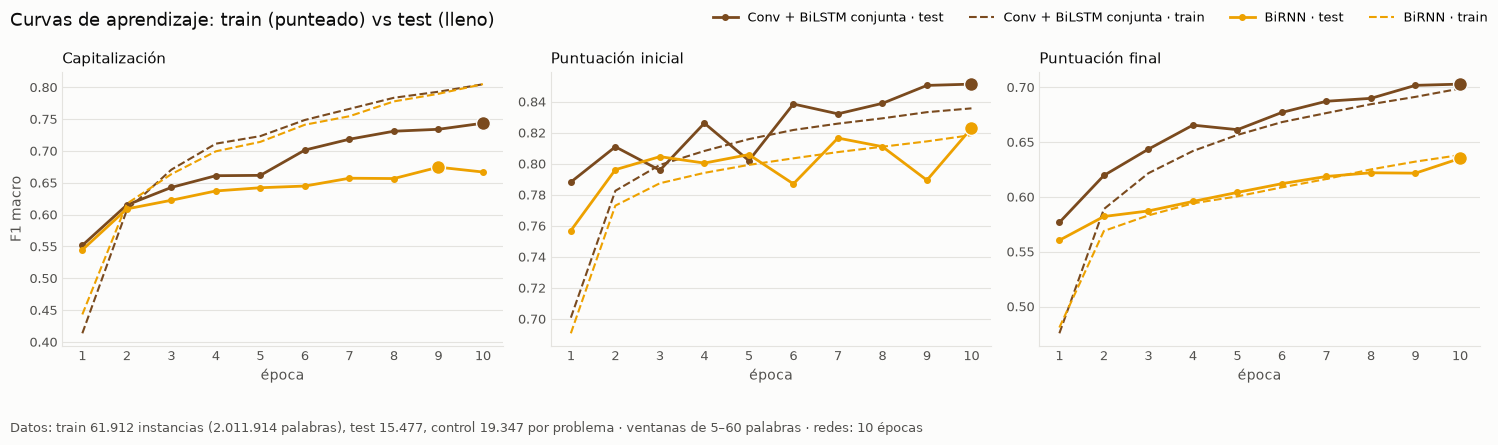

In [6]:
show_and_save(C.plot_train_test_curves(report), "3_curvas_f1_train_test")

## 4. Loss por época

Una curva por red entrenada (la conjunta se entrenó una sola vez para los dos problemas). No comparar escalas entre
paneles: la loss de la conjunta suma las 3 tareas.

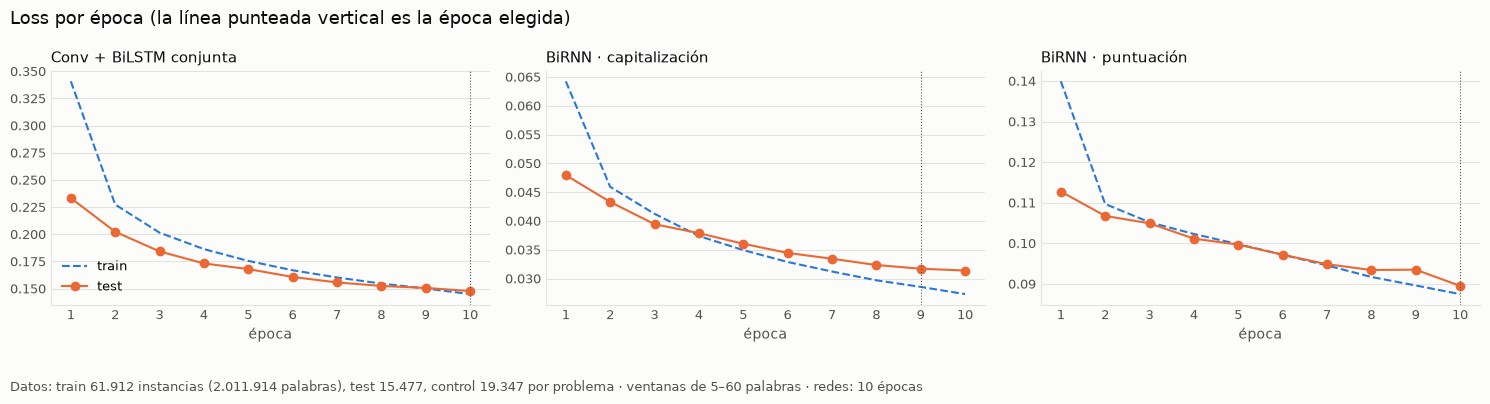

In [7]:
show_and_save(C.plot_loss_curves(report), "4_loss")

## 5. F1 por clase

Las clases raras (`¿`, `?`, `,`, MiXta, MAYÚS) son las que bajan el F1 macro.

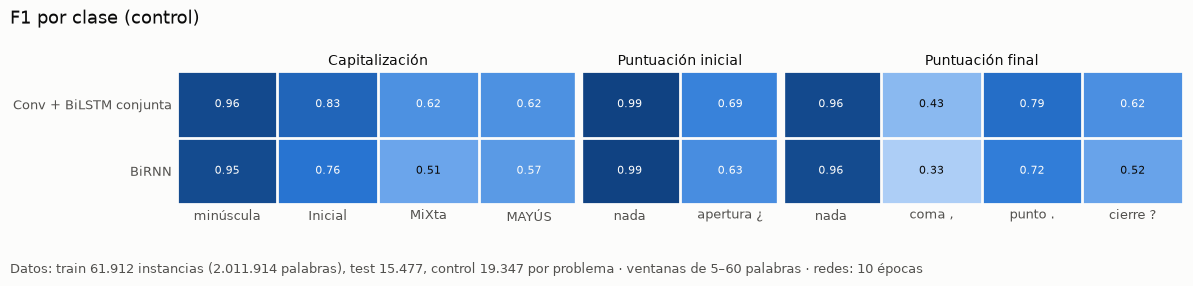

In [8]:
show_and_save(P.plot_class_f1(report, SPLIT), "5_f1_por_clase")

## 6. Precisión vs recall por clase

Con `class_weight_power = 0.5` las clases raras tenían recall mucho mayor que precisión: se predecían de más.
Con 0.25 deberían quedar más parejas.

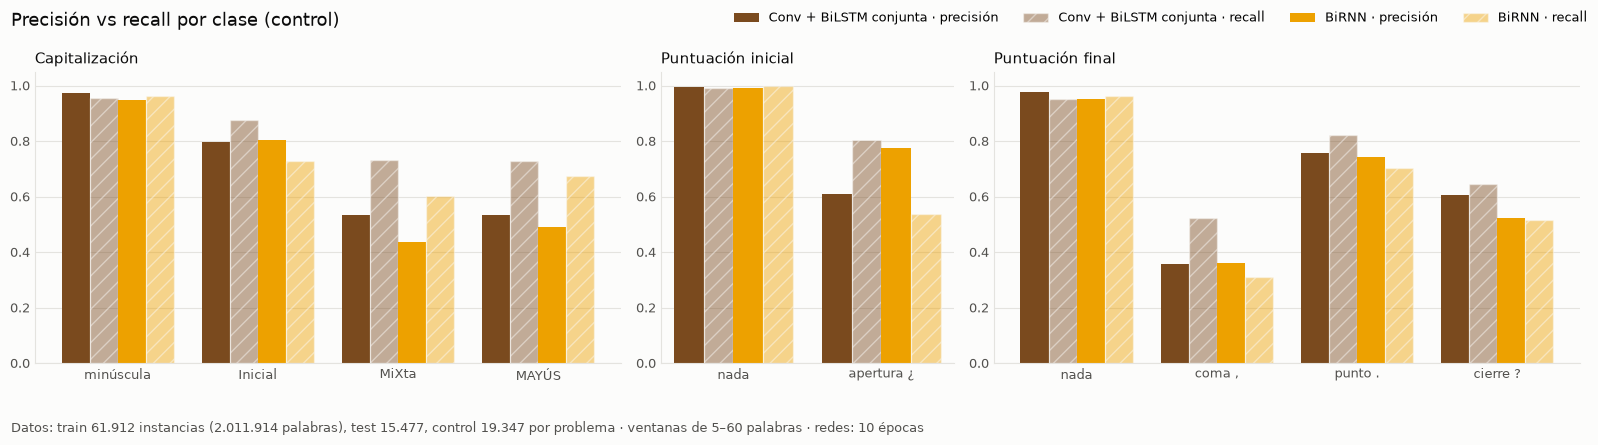

In [9]:
show_and_save(C.plot_precision_recall(report, SPLIT), "6_precision_recall")

## 7. Matrices de confusión

Normalizadas por fila: cada fila muestra a dónde fueron las palabras de esa clase real (la diagonal es el recall).

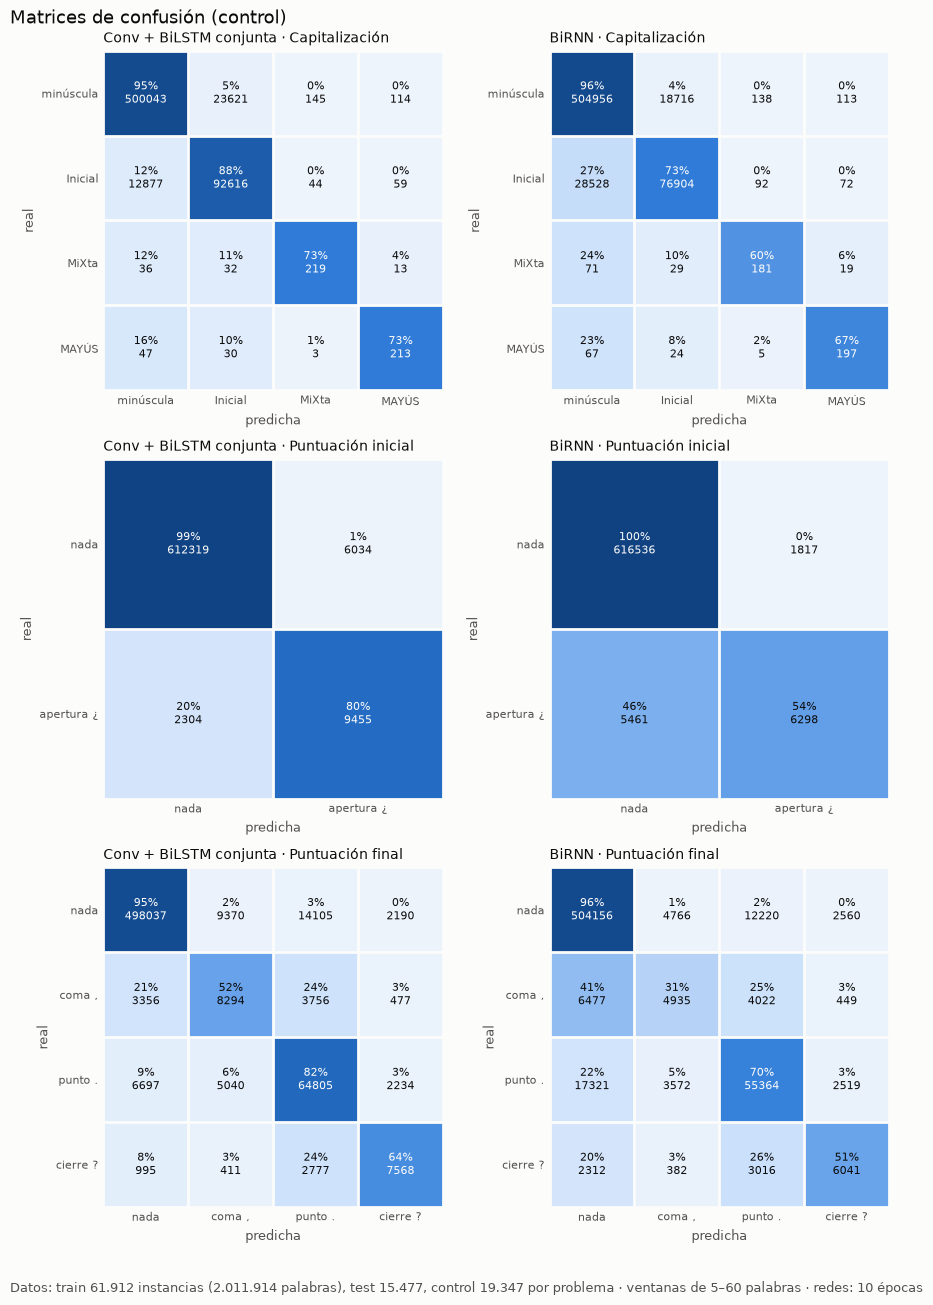

In [10]:
show_and_save(C.plot_confusions_side_by_side(report, SPLIT), "7_confusion")

## 8. Conclusiones

F1 macro en control (entre paréntesis, la diferencia con el mejor resultado previo del mismo modelo):

| Modelo | Capitalización | Punt. inicial | Punt. final | Promedio |
|---|---|---|---|---|
| **Conv + BiLSTM conjunta** | **0.758** (+0.141) | **0.844** (+0.090) | **0.701** (+0.118) | **0.767** |
| BiRNN | 0.698 (+0.093) | 0.814 (+0.025) | 0.633 (+0.086) | 0.715 |

1. **La Conv + BiLSTM conjunta es el mejor modelo para los dos problemas**, y gana en todas las tareas y clases. Antes
   la BiRNN le ganaba en `¿`.
2. **Bajar `class_weight_power` a 0.25 equilibró precisión y recall de las clases raras.** En la conjunta, la precisión
   de `¿` pasó de 0.30 a 0.61, la de MiXta de 0.31 a 0.53 y la de `?` de 0.38 a 0.61, perdiendo poco recall. En la BiRNN
   de puntuación se pasó un poco: `¿` quedó con precisión 0.78 y recall 0.54 (ahora lo predice de menos).
3. **La conjunta todavía no llegó a su techo**: su mejor época fue la última (10/10) y la brecha entre train y test es
   mínima (~0.01). Con más épocas probablemente siga mejorando.
4. **La BiRNN de capitalización empieza a sobreajustar**: train llega a 0.805 y test a 0.667 (brecha de 0.14), y test
   baja en la época 10. No tiene dropout ni weight decay.
5. **La coma sigue siendo la clase más difícil** (F1 0.43 en la conjunta): muchas veces es opcional incluso para una
   persona.
6. **Limitación**: las corridas cambian tres cosas a la vez (épocas, peso de clase y weight decay), así que no se puede
   atribuir la mejora a cada una. En la BiRNN de capitalización el weight decay no cambió (es 0), así que su mejora
   viene de las épocas y del peso de clase.